# Data Challenge 2026–2027 · EasyVista — SLA prediction in ITSM
## Exploratory analysis

The two tasks of the challenge:
1. **Classification**: will the ticket's SLA be violated?
2. **Regression**: how long will it take to resolve the ticket?

Contents:
1. Loading and cleaning
2. Target definition and first plots
3. Data quality: missing values and anomalies
4. Dataset composition: categories and volume over time
5. Targets by subgroup: violation rate and resolution time by type, channel and SLA
6. When tickets arrive: hour, day of the week, off-hours and holidays
7. Submitters: concentration and history
8. Link between the two targets
9. Key takeaways for the modelling

Feature engineering and models are in `SLA_baseline_v2.ipynb`.

**Requirements:** `pandas numpy matplotlib holidays`

### Setup (Colab)
Run these two cells first. The first one writes `prep.py` (shared data preparation) into the working folder, so you do not need to upload it. The second installs the missing libraries and asks you to upload `raw_EV_data_challenge.csv`.

In [1]:
%%writefile prep.py
"""Shared data preparation for the EasyVista Data Challenge (SLA prediction).

Usage:
    from prep import load_data, CAT_CREATE, NUM_CREATE, ...
    df = load_data("raw_EV_data_challenge.csv")

Changes vs. the first version (see the work guide, section 3):
  * calendar features use Paris local time instead of UTC                     (issue 5)
  * `sla_nominal`: deadline length known at submission, replaces the
    recorded `sla_real_hours`, which looks recomputed during the ticket life (issue 1)
  * `open_recent_30d`: alternative load counter on the last 30 days only (issue 3).
    The rolling CV prefers the original cumulative counter, so it stays in NUM_CREATE
    and the 30-day version is kept in RECENT_LOAD for the ablation
  * `never_closed` flag, to report metrics with and without these tickets    (issue 4)
"""
import numpy as np
import pandas as pd
import holidays

DATE_COLS = ["SUBMIT_DATE_UT", "MAX_RESOLUTION_DATE_UT", "END_DATE_UT"]
VALID_START = pd.Timestamp("2024-01-01")
TEST_START = pd.Timestamp("2024-04-01")
REG_TEST_END = pd.Timestamp("2024-08-01")   # margin against censoring for the "plain" regression test
LOCAL_TZ = "Europe/Paris"                   # timestamps are UTC; business hours follow Paris time
LOAD_WINDOW_DAYS = 30                       # look-back window for the load feature

# Features known when the ticket is created (no leakage)
CAT_CREATE = ["SD_CATALOG_PATH_EN", "URGENCY_VALUE", "IMPACT_VALUE", "SLA_DELAY", "REQUEST_ORIGIN", "SUBMITTED_BY_ID"]
NUM_CREATE = ["sla_nominal", "hour", "dow", "month", "is_weekend", "is_holiday", "off_hours",
              "submitter_missing", "open_tickets_at_submit", "open_same_type_at_submit",
              "arrivals_24h", "arrivals_7d", "submitter_prev_tickets"]

# Kept only for ablations
LEAK_SUSPECT = ["sla_real_hours"]                                  # recorded deadline length (likely leak)
RECENT_LOAD = ["open_recent_30d", "open_recent_30d_same_type"]     # 30-day load counters (no time trend)
CUMULATIVE_LOAD = ["open_tickets_at_submit", "open_same_type_at_submit"]  # in NUM_CREATE; trends with time

# "Oracle" features, known only after the ticket is closed (upper bound, never for production)
CAT_ORACLE = ["LAST_DONE_BY_ID", "STATUS_EN"]
NUM_ORACLE = ["nb_actions"]

MIN_HOURS = 1 / 60  # 1 minute: minimum duration, avoids log(0) in survival models


def load_data(path):
    df = pd.read_csv(path, sep=";", na_values=["NULL"])
    for c in DATE_COLS:
        df[c] = pd.to_datetime(df[c]).astype("datetime64[ns]")
    df = df.sort_values("SUBMIT_DATE_UT").reset_index(drop=True)

    # Impossible closing dates (before submission, e.g. 1900-01-01) -> missing
    df.loc[df["END_DATE_UT"] < df["SUBMIT_DATE_UT"], "END_DATE_UT"] = pd.NaT
    extract = max(df["SUBMIT_DATE_UT"].max(), df["END_DATE_UT"].max())
    df.attrs["extract_date"] = extract

    # Targets, as known at the extraction date
    df["viol"] = viol_as_of(df, extract)
    df["res_hours"] = (df["END_DATE_UT"] - df["SUBMIT_DATE_UT"]).dt.total_seconds() / 3600
    df["never_closed"] = df["END_DATE_UT"].isna().astype(int)

    t = df["SUBMIT_DATE_UT"]
    df["split"] = np.where(t < VALID_START, "train", np.where(t < TEST_START, "valid", "test"))
    _add_features(df)
    return df


def viol_as_of(df, cutoff):
    """SLA-violation label as it would have been known at date `cutoff`.
    1   = deadline passed without closure (or closed after the deadline), known if deadline < cutoff
    0   = closed within the deadline, known if closure <= cutoff
    NaN = still unknown at that date (or ticket without SLA)."""
    end, dl = df["END_DATE_UT"], df["MAX_RESOLUTION_DATE_UT"]
    out = pd.Series(np.nan, index=df.index)
    ok0 = dl.notna() & end.notna() & (end <= dl) & (end <= cutoff)
    ok1 = dl.notna() & (dl < cutoff) & (end.isna() | (end > dl))
    out[ok0] = 0.0
    out[ok1] = 1.0
    return out


def duration_as_of(df, cutoff):
    """Duration in hours and event indicator as known at date `cutoff`.
    Tickets not closed by `cutoff` are right-censored at (cutoff - submission)."""
    end = df["END_DATE_UT"]
    observed = end.notna() & (end <= cutoff)
    stop = end.where(observed, cutoff)
    dur = ((stop - df["SUBMIT_DATE_UT"]).dt.total_seconds() / 3600).clip(lower=MIN_HOURS)
    return dur, observed.astype(int)


def _open_recent(sub_ns, end_ns, window_ns):
    """For each ticket: how many tickets submitted in the previous `window_ns` are still open at its submission.
    Arrays must be sorted by submission time. Uses only information available at submission."""
    first = np.searchsorted(sub_ns, sub_ns - window_ns, side="left")
    before = np.searchsorted(sub_ns, sub_ns, side="left")
    out = np.empty(len(sub_ns), dtype=np.int64)
    for i in range(len(sub_ns)):
        out[i] = np.count_nonzero(end_ns[first[i]:before[i]] >= sub_ns[i])
    return out


def _add_features(df):
    t = df["SUBMIT_DATE_UT"]

    # Recorded deadline length (suspected leakage: kept only for ablations)
    df["sla_real_hours"] = (df["MAX_RESOLUTION_DATE_UT"] - t).dt.total_seconds() / 3600

    # Calendar features in Paris local time (handles daylight saving)
    loc = t.dt.tz_localize("UTC").dt.tz_convert(LOCAL_TZ).dt.tz_localize(None)
    df["hour"] = loc.dt.hour
    df["dow"] = loc.dt.dayofweek
    df["month"] = loc.dt.month
    df["is_weekend"] = (df["dow"] >= 5).astype(int)
    fr = holidays.France(years=range(loc.dt.year.min(), loc.dt.year.max() + 1))
    df["is_holiday"] = loc.dt.date.map(lambda d: d in fr).astype(int)
    df["off_hours"] = ((df["hour"] < 8) | (df["hour"] >= 18) | (df["is_weekend"] == 1)
                       | (df["is_holiday"] == 1)).astype(int)
    df["submitter_missing"] = df["SUBMITTED_BY_ID"].isna().astype(int)

    # Nominal deadline length, known at submission: median recorded length for the same
    # SLA_DELAY and hour of the week, estimated on the training period only
    # (a missing SLA_DELAY is treated as its own group: ~130 tickets have a deadline but no SLA_DELAY).
    # The median is robust to the ~9% of deadlines that are extended later on.
    df["hour_of_week"] = df["dow"] * 24 + df["hour"]
    tr = df["split"] == "train"
    by_slot = df[tr].groupby(["SLA_DELAY", "hour_of_week"], dropna=False)["sla_real_hours"].median().rename("_slot")
    by_delay = df[tr].groupby("SLA_DELAY", dropna=False)["sla_real_hours"].median().rename("_delay")
    nom = (df[["SLA_DELAY", "hour_of_week"]]
           .merge(by_slot, left_on=["SLA_DELAY", "hour_of_week"], right_index=True, how="left")
           .merge(by_delay, left_on="SLA_DELAY", right_index=True, how="left"))
    df["sla_nominal"] = nom["_slot"].fillna(nom["_delay"]).values   # fallback: median per SLA_DELAY
    # Diagnostic only (uses the recorded deadline): deadline clearly longer than the nominal one
    df["deadline_extended"] = ((df["sla_real_hours"] > 1.5 * df["sla_nominal"])
                               & (df["sla_real_hours"] - df["sla_nominal"] > 24)).astype(int)

    # System load: only information known at submission
    sub_ns = t.values.astype("datetime64[ns]").astype("int64")
    end_ns = df["END_DATE_UT"].values.astype("datetime64[ns]").astype("int64")
    end_ns = np.where(df["END_DATE_UT"].isna(), np.iinfo("int64").max, end_ns)  # never closed = open forever
    n_before = np.searchsorted(sub_ns, sub_ns, side="left")
    day = np.int64(24 * 3600 * 10**9)

    # Cumulative counters (all tickets ever opened and still open). They grow with time because
    # never-closed tickets pile up and the data starts at zero in Sep 2022, but the rolling CV
    # still prefers them to the 30-day version: keep them, and do not read their SHAP plot as a pure load effect
    df["open_tickets_at_submit"] = n_before - np.searchsorted(np.sort(end_ns), sub_ns, side="left")
    df["open_same_type_at_submit"] = 0
    # 30-day counters: only tickets submitted in the last LOAD_WINDOW_DAYS (the first month of data is a warm-up)
    win = LOAD_WINDOW_DAYS * day
    df["open_recent_30d"] = _open_recent(sub_ns, end_ns, win)
    df["open_recent_30d_same_type"] = 0
    for _, idx in df.groupby("SD_CATALOG_PATH_EN").groups.items():
        s, e = sub_ns[idx], end_ns[idx]
        df.loc[idx, "open_same_type_at_submit"] = np.searchsorted(s, s, side="left") - np.searchsorted(np.sort(e), s, side="left")
        df.loc[idx, "open_recent_30d_same_type"] = _open_recent(s, e, win)

    df["arrivals_24h"] = n_before - np.searchsorted(sub_ns, sub_ns - day, side="left")
    df["arrivals_7d"] = n_before - np.searchsorted(sub_ns, sub_ns - 7 * day, side="left")

    # Submitter history: number of tickets opened before this one (-1 = unknown submitter)
    df["submitter_prev_tickets"] = df.groupby("SUBMITTED_BY_ID").cumcount()
    df.loc[df["SUBMITTED_BY_ID"].isna(), "submitter_prev_tickets"] = -1


def prepare_cats(frame, cats, train_mask, min_count=20):
    """Categoricals as 'category' dtype (LightGBM/XGBoost); rare or unseen levels in train -> '__other__'."""
    X = frame.copy()
    for c in cats:
        s = X[c].astype("string").fillna("__missing__")
        vc = s[train_mask].value_counts()
        keep = set(vc[vc >= min_count].index)
        X[c] = pd.Categorical(s.where(s.isin(keep), "__other__"))
    return X


Overwriting prep.py


In [2]:
# Colab setup: install the libraries that Colab does not preinstall,
# then upload the CSV if it is not in the working folder yet (prep.py is written by the cell above).
!pip install -q catboost lifelines holidays
import os
if not os.path.exists("raw_EV_data_challenge.csv"):
    try:
        from google.colab import files
        print("Please upload raw_EV_data_challenge.csv")
        files.upload()
    except ImportError:
        print("Put raw_EV_data_challenge.csv next to the notebook.")
else:
    print("CSV found.")

CSV found.


In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
DATA_PATH = "raw_EV_data_challenge.csv"

# palette (colorblind-safe, fixed order)
BLUE, ORANGE, AQUA, GRAY, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85", "#e1e0d9"
INK = "#3d3d3a"  # text colour for annotations
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "figure.dpi": 110})
pd.set_option("display.width", 140)

## 1. Loading and cleaning

In [4]:
# All data preparation now lives in prep.py, so both notebooks use exactly the same
# targets and features. Keep the plotting cell of section 2 as it is.
from prep import (load_data, prepare_cats, CAT_CREATE, NUM_CREATE, CAT_ORACLE, NUM_ORACLE,
                  LEAK_SUSPECT, VALID_START, TEST_START, REG_TEST_END)

df = load_data(DATA_PATH)
EXTRACT_DATE = df.attrs["extract_date"]
t = df["SUBMIT_DATE_UT"]
print(df.shape, "| period:", t.min(), "->", t.max(), "| extraction date:", EXTRACT_DATE)
print("tickets with a violation label:", df.viol.notna().sum(),
      "| of which never closed and overdue:", (df.viol.notna() & (df.never_closed == 1)).sum())
print("violation rate:", round(df.viol.mean(), 3), "| closed tickets (regression):", df.res_hours.notna().sum())
print(df.groupby("split").agg(n=("REQUEST_ID", "size"), viol_rate=("viol", "mean"),
                              res_median_h=("res_hours", "median")).round(3).loc[["train", "valid", "test"]])


(64175, 35) | period: 2022-09-16 06:04:44 -> 2024-09-16 18:25:36.993000 | extraction date: 2024-09-16 18:31:03.483000
tickets with a violation label: 59925 | of which never closed and overdue: 924
violation rate: 0.259 | closed tickets (regression): 60911
           n  viol_rate  res_median_h
split                                
train  38402      0.260        17.194
valid   9312      0.242         8.118
test   16461      0.265         7.213


## 2. Targets and exploratory analysis

**SLA violation** (`viol`), defined only for tickets with an SLA (`MAX_RESOLUTION_DATE_UT` present):
- closed ticket → `viol = END_DATE > MAX_RESOLUTION_DATE`
- ticket **not closed** but with the deadline already passed at the extraction date → `viol = 1` (the SLA is certainly violated)
- ticket not closed with a future deadline → unknown label, excluded

**Resolution time** (`res_hours`): calendar hours between opening and closing; for the regression we use `log1p(res_hours)` because of the long tail. Tickets that are not closed are **right-censored** (see next steps: survival analysis).

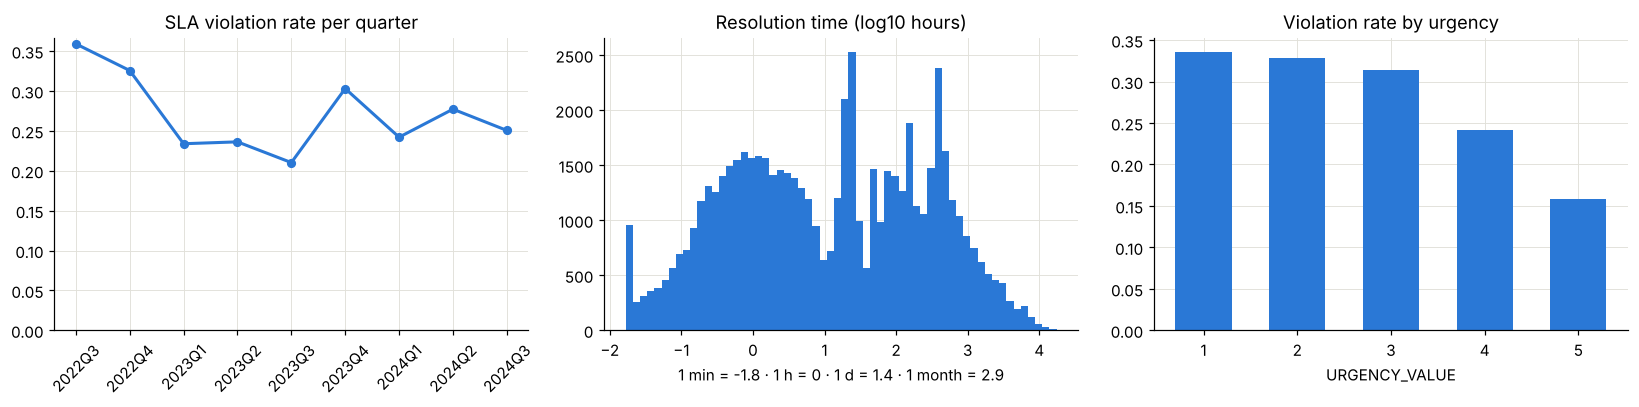

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

q = df.dropna(subset=["viol"]).groupby(df.SUBMIT_DATE_UT.dt.to_period("Q"))["viol"].mean()
axes[0].plot(q.index.astype(str), q.values, color=BLUE, lw=2, marker="o", ms=5)
axes[0].set_title("SLA violation rate per quarter")
axes[0].set_ylim(0, None); axes[0].tick_params(axis="x", rotation=45)

axes[1].hist(np.log10(df.res_hours.dropna().clip(lower=1/60)), bins=60, color=BLUE)
axes[1].set_title("Resolution time (log10 hours)")
axes[1].set_xlabel("1 min = -1.8 · 1 h = 0 · 1 d = 1.4 · 1 month = 2.9")

u = df.dropna(subset=["viol"]).groupby("URGENCY_VALUE")["viol"].mean()
axes[2].bar(u.index.astype(str), u.values, color=BLUE, width=0.6)
axes[2].set_title("Violation rate by urgency"); axes[2].set_xlabel("URGENCY_VALUE")
plt.tight_layout(); plt.show()

## 3. Data quality
Missing values per column in the raw file, then the anomalies that `prep.py` has to handle.

In [6]:
raw = pd.read_csv(DATA_PATH, sep=";", na_values=["NULL"])
for c in ["SUBMIT_DATE_UT", "MAX_RESOLUTION_DATE_UT", "END_DATE_UT"]:
    raw[c] = pd.to_datetime(raw[c])

missing = raw.isna().mean().mul(100).round(1).sort_values(ascending=False)
display(missing[missing > 0].rename("missing_%").to_frame())

checks = {
    "duplicated REQUEST_ID": raw["REQUEST_ID"].duplicated().sum(),
    "closing date before submission (set to missing)": (raw["END_DATE_UT"] < raw["SUBMIT_DATE_UT"]).sum(),
    "never closed": df["never_closed"].sum(),
    "no SLA deadline": df["MAX_RESOLUTION_DATE_UT"].isna().sum(),
    "deadline but no SLA_DELAY": (df["MAX_RESOLUTION_DATE_UT"].notna() & df["SLA_DELAY"].isna()).sum(),
    "deadline extended after submission": df["deadline_extended"].sum(),
    "resolved in under 1 minute": (df["res_hours"] < 1 / 60).sum(),
}
pd.DataFrame({"n": checks}).assign(share=lambda x: (x["n"] / len(df)).round(3))

,missing_%
SUBMITTED_BY_ID,14.4
STATUS_EN,9.3
SLA_DELAY,6.4
MAX_RESOLUTION_DATE_UT,6.3
LAST_DONE_BY_ID,5.5
END_DATE_UT,5.0
REQUEST_ORIGIN,1.1


,n,share
duplicated REQUEST_ID,0,0.000
closing date before submission (set to missing),66,0.001
never closed,3264,0.051
no SLA deadline,4069,0.063
deadline but no SLA_DELAY,131,0.002
deadline extended after submission,5761,0.090
resolved in under 1 minute,721,0.011


**Reading.** No duplicated tickets. The submitter is missing for 14.4% of the tickets (mostly emails and phone calls), so "unknown submitter" has to be a category of its own. 66 closing dates are earlier than the submission (e.g. 1900-01-01) and are treated as missing. 5.1% of the tickets were never closed and 6.3% have no SLA deadline. 9% of the deadlines look extended after the ticket was opened, which is why the models use the *nominal* deadline (`sla_nominal`) instead of the recorded one. 1.1% of the tickets are closed in less than a minute.

## 4. Dataset composition

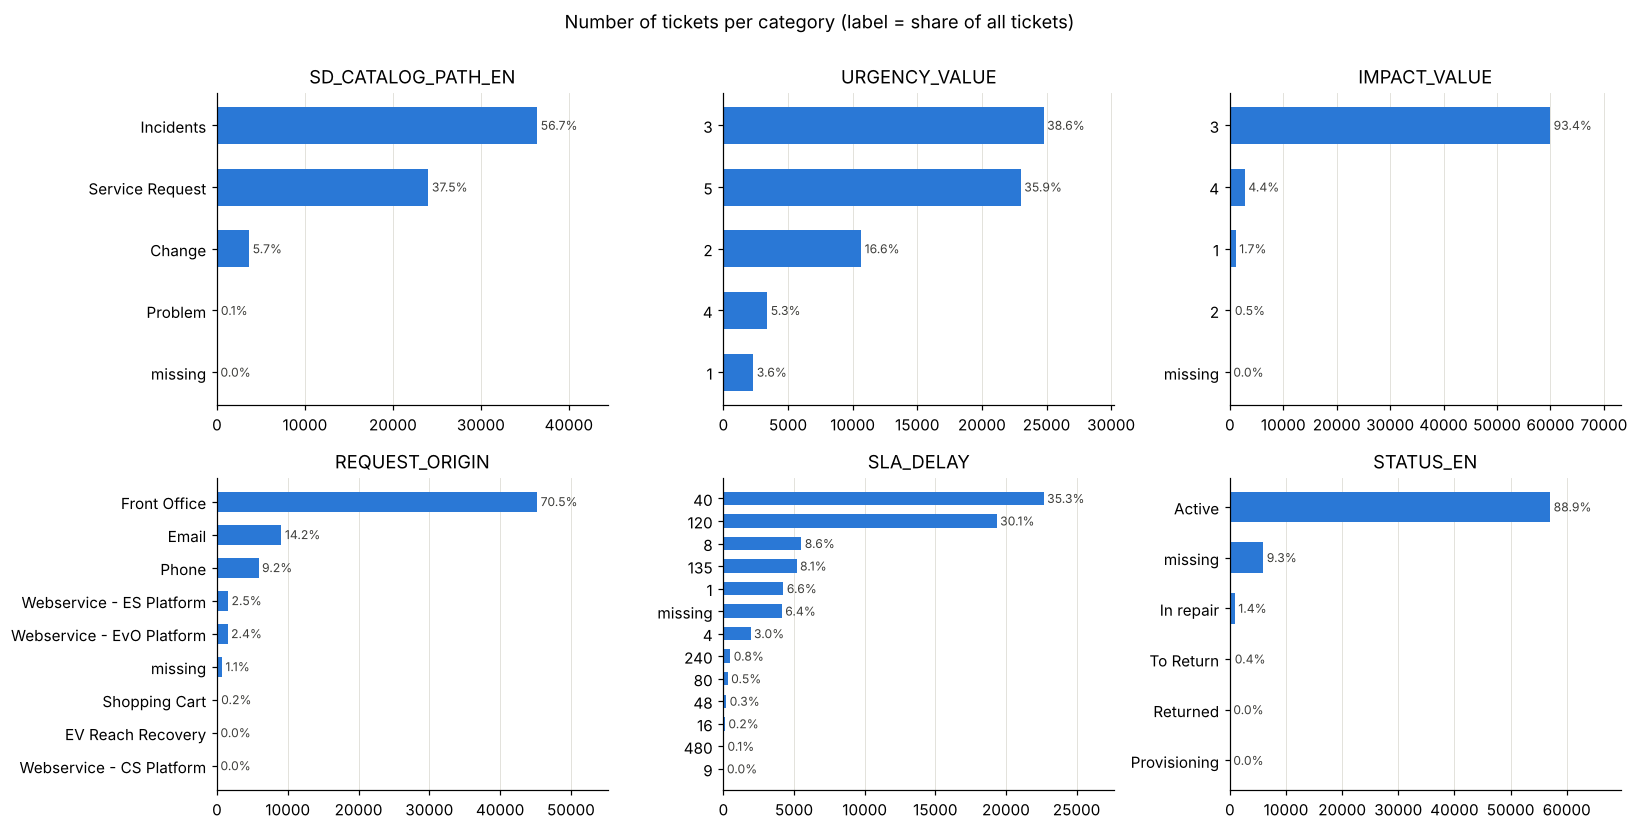

In [7]:
CAT_COLS = ["SD_CATALOG_PATH_EN", "URGENCY_VALUE", "IMPACT_VALUE", "REQUEST_ORIGIN", "SLA_DELAY", "STATUS_EN"]

def as_label(s):
    """Categorical column as readable strings (numeric codes without '.0'), missing as 'missing'."""
    if pd.api.types.is_numeric_dtype(s):
        s = s.astype("Int64")
    return s.astype("string").fillna("missing")

fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, c in zip(axes.flat, CAT_COLS):
    vc = as_label(df[c]).value_counts().iloc[::-1]          # largest on top
    ax.barh(vc.index, vc.values, color=BLUE, height=0.6)
    for y, v in enumerate(vc.values):
        ax.text(v, y, f" {v / len(df):.1%}", va="center", fontsize=8, color=INK)
    ax.set_title(c); ax.grid(axis="y", visible=False)
    ax.set_xlim(0, vc.max() * 1.22)
fig.suptitle("Number of tickets per category (label = share of all tickets)", y=1.0)
plt.tight_layout(); plt.show()

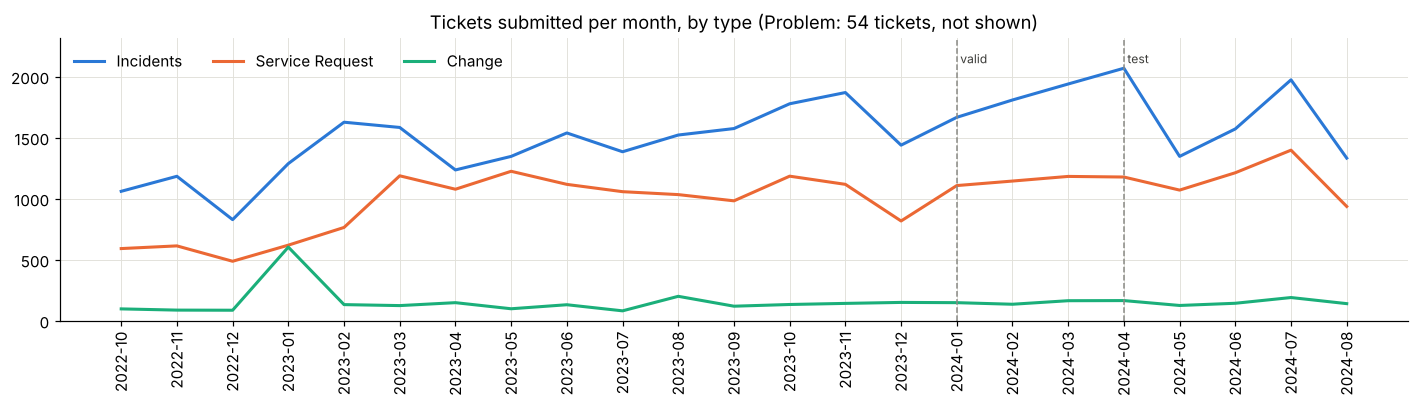

In [8]:
# Monthly volume by ticket type (the first and last months are partial and are dropped)
m = df.groupby([df["SUBMIT_DATE_UT"].dt.to_period("M"), "SD_CATALOG_PATH_EN"]).size().unstack(fill_value=0)
m = m.iloc[1:-1]
fig, ax = plt.subplots(figsize=(13, 3.8))
for cat, col in [("Incidents", BLUE), ("Service Request", ORANGE), ("Change", AQUA)]:
    ax.plot(m.index.astype(str), m[cat], color=col, lw=2, label=cat)
ax.axvline(str(TEST_START.to_period("M")), color=GRAY, lw=1, ls="--")
ax.axvline(str(VALID_START.to_period("M")), color=GRAY, lw=1, ls="--")
ax.text(str(VALID_START.to_period("M")), m.values.max() * 1.02, " valid", fontsize=8, color=INK)
ax.text(str(TEST_START.to_period("M")), m.values.max() * 1.02, " test", fontsize=8, color=INK)
ax.set_title("Tickets submitted per month, by type (Problem: 54 tickets, not shown)")
ax.set_ylim(0, m.values.max() * 1.12); ax.tick_params(axis="x", rotation=90)
ax.legend(frameon=False, ncol=3, loc="upper left")
plt.tight_layout(); plt.show()

**Reading.** Incidents (57%) and Service Requests (38%) make up almost the whole dataset; Change is 6% and Problem only 54 tickets. `IMPACT_VALUE` is 3 for 93% of the tickets, so it carries little information. 70% of the tickets come from the Front Office. Two SLA levels, 40 and 120 business hours, cover 65% of the tickets. `STATUS_EN` is "Active" for 89% of the tickets and is known only afterwards (oracle feature).

The volume of Incidents roughly doubles between the end of 2022 and spring 2024, with a dip in December 2023. Change shows a one-off spike in January 2023. Because volume and mix change over time, a random train/test split would be too optimistic: we split by date.

## 5. Targets by subgroup
Violation rate and resolution time across the main categories. The dashed line is the overall violation rate.

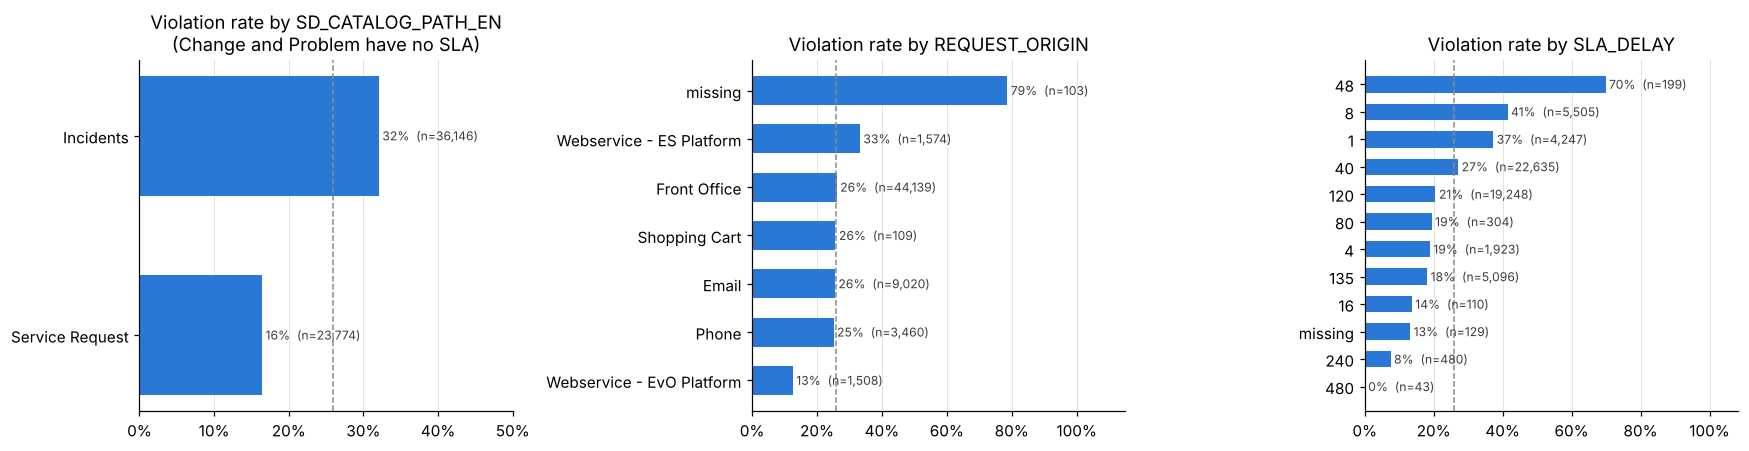

In [9]:
from matplotlib.ticker import PercentFormatter

lab = df[df["viol"].notna()]
overall = lab["viol"].mean()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, c in zip(axes, ["SD_CATALOG_PATH_EN", "REQUEST_ORIGIN", "SLA_DELAY"]):
    g = lab.groupby(as_label(lab[c]))["viol"].agg(["mean", "size"])
    g = g[g["size"] >= 30].sort_values("mean")              # groups with fewer than 30 tickets are hidden
    ax.barh(g.index, g["mean"], color=BLUE, height=0.6)
    for y, (r, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(r, y, f" {r:.0%}  (n={n:,})", va="center", fontsize=8, color=INK)
    ax.axvline(overall, color=GRAY, lw=1, ls="--")
    ax.set_xlim(0, min(g["mean"].max() * 1.55, 1.15)); ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.set_xticks([t for t in ax.get_xticks() if t <= 1])
    ax.set_title(f"Violation rate by {c}")
axes[0].set_title("Violation rate by SD_CATALOG_PATH_EN\n(Change and Problem have no SLA)")
plt.tight_layout(); plt.show()

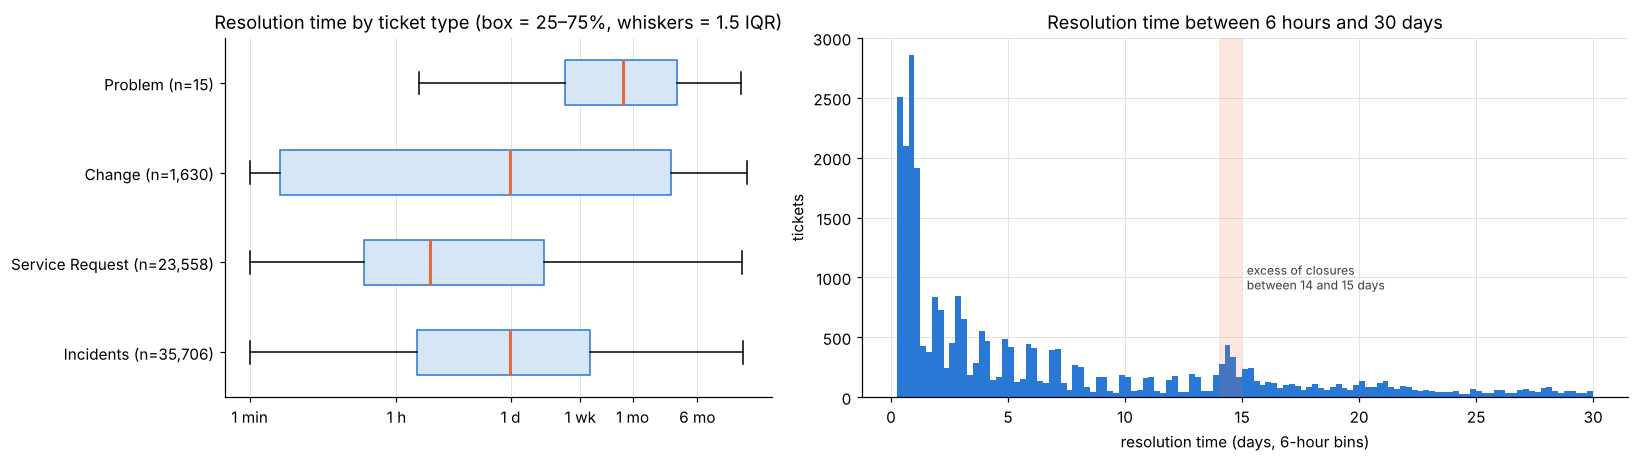

closed after 13-14 / 14-15 / 15-16 days: [np.int64(450), np.int64(1222), np.int64(717)]


,count,mean,std,min,25%,50%,75%,90%,max
SD_CATALOG_PATH_EN,,,,,,,,,
Incidents,35706.0,274.0,767.8,0.0,1.8,23.5,219.1,660.8,15653.0
Service Request,23558.0,196.1,728.5,0.0,0.4,2.6,61.3,432.7,15171.1
Change,1630.0,1426.4,2532.4,0.0,0.0,23.4,2118.9,4898.4,17478.6
Problem,15.0,2463.8,4356.9,1.9,110.6,553.3,2501.5,7606.3,14734.6


In [10]:
closed = df[df["res_hours"].notna()]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1, 1.4]})

order = ["Incidents", "Service Request", "Change", "Problem"]
data = [np.log10(closed.loc[closed["SD_CATALOG_PATH_EN"] == c, "res_hours"].clip(lower=1 / 60)) for c in order]
bp = axes[0].boxplot(data, vert=False, widths=0.5, showfliers=False, patch_artist=True,
                     medianprops=dict(color=ORANGE, lw=2))
for b in bp["boxes"]:
    b.set(facecolor="#d6e6f7", edgecolor=BLUE)
axes[0].set_yticks(range(1, 5), [f"{c} (n={len(x):,})" for c, x in zip(order, data)])
ticks = {"1 min": 1 / 60, "1 h": 1, "1 d": 24, "1 wk": 168, "1 mo": 720, "6 mo": 4380}
axes[0].set_xticks(np.log10(list(ticks.values())), list(ticks.keys()))
axes[0].set_title("Resolution time by ticket type (box = 25–75%, whiskers = 1.5 IQR)")
axes[0].grid(axis="y", visible=False)

# Zoom on 6 hours - 30 days: daily waves (closures happen in working hours) and a spike at 14-15 days
days = closed["res_hours"] / 24
axes[1].hist(days[(days >= 0.25) & (days <= 30)], bins=np.arange(0.25, 30.01, 0.25), color=BLUE)
axes[1].axvspan(14, 15, color=ORANGE, alpha=0.15, lw=0)
axes[1].text(15.2, axes[1].get_ylim()[1] * 0.3, "excess of closures\nbetween 14 and 15 days", color=INK, fontsize=8)
axes[1].set_xlabel("resolution time (days, 6-hour bins)"); axes[1].set_ylabel("tickets")
axes[1].set_title("Resolution time between 6 hours and 30 days")
plt.tight_layout(); plt.show()

n_day = {k: ((days >= k) & (days < k + 1)).sum() for k in [13, 14, 15]}
print("closed after 13-14 / 14-15 / 15-16 days:", list(n_day.values()))
closed.groupby("SD_CATALOG_PATH_EN")["res_hours"].describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(1).loc[order]

**Reading.** Only Incidents and Service Requests have an SLA. Incidents are violated twice as often (32% vs 16%). Among channels, *Webservice - ES Platform* is above average (33%) and *EvO Platform* well below (13%); the 103 tickets without an origin are violated 79% of the time, a small but odd group to check with EasyVista. Short deadlines are violated much more often: 41% for 8 hours and 37% for 1 hour, against 8% for 240 hours and none for 480.

Resolution times span six orders of magnitude: 26% of the closed tickets are resolved within an hour and 58% within a day, while the 99th percentile is around half a year. Service Requests are fast (median 2.6 h), Incidents and Changes slower (median about 23 h), and Changes have the widest spread. This long tail is why the regression target is `log1p(hours)`. The histogram shows daily waves (closures happen in working hours) and an excess of closures between 14 and 15 days (1,222 tickets against 450 and 717 in the days before and after, mostly Incidents): probably an automatic closure after two weeks, to confirm with EasyVista.

## 6. When tickets arrive
Hour and day of the week are in Paris local time (as built in `prep.py`).

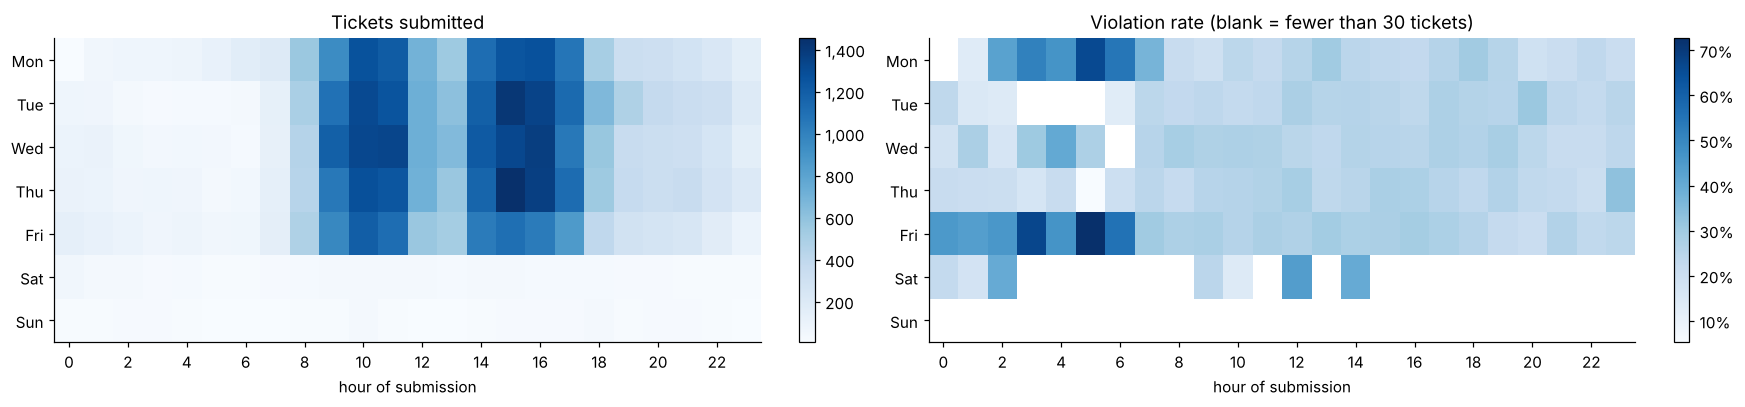

n  viol_rate  median_res_hours
condition                                        value                                    
weekend                                          no     63105      0.259            11.518
                                                 yes     1070      0.247            43.385
off hours (before 8, after 18, weekend, holiday) no     49951      0.256             6.280
                                                 yes    14224      0.268            20.404
French public holiday                            no     63456      0.259            12.539
                                                 yes      719      0.244            23.932

In [11]:
DOW = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
vol = df.pivot_table(index="dow", columns="hour", values="REQUEST_ID", aggfunc="size", fill_value=0)
vr = lab.pivot_table(index="dow", columns="hour", values="viol", aggfunc="mean")
vr_n = lab.pivot_table(index="dow", columns="hour", values="viol", aggfunc="size")
vr = vr.where(vr_n >= 30)                                   # hide cells with fewer than 30 tickets

fig, axes = plt.subplots(1, 2, figsize=(16, 3.8))
for ax, mat, title, fmt in [(axes[0], vol, "Tickets submitted", "{:,.0f}"),
                            (axes[1], vr, "Violation rate (blank = fewer than 30 tickets)", "{:.0%}")]:
    im = ax.imshow(mat.values, aspect="auto", cmap="Blues")
    ax.set_yticks(range(7), DOW); ax.set_xticks(range(0, 24, 2), range(0, 24, 2))
    ax.set_xlabel("hour of submission"); ax.set_title(title); ax.grid(False)
    cb = fig.colorbar(im, ax=ax, fraction=0.025)
    cb.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _, f=fmt: f.format(v)))
plt.tight_layout(); plt.show()

rows = []
for c, name in [("is_weekend", "weekend"), ("off_hours", "off hours (before 8, after 18, weekend, holiday)"),
                ("is_holiday", "French public holiday")]:
    for flag in [0, 1]:
        mk = df[c] == flag
        rows.append(dict(condition=name, value="yes" if flag else "no", n=mk.sum(),
                         viol_rate=df.loc[mk, "viol"].mean(), median_res_hours=df.loc[mk, "res_hours"].median()))
pd.DataFrame(rows).set_index(["condition", "value"]).round(3)

**Reading.** Tickets arrive on weekdays between 8:00 and 18:00, with a dip at lunchtime; weekends are almost empty. The violation rate is highest for tickets opened at night on Monday and Friday (up to about 70%), when nobody can pick them up before the clock starts running. Overall, off-hours tickets are only slightly more often violated (26.8% vs 25.6%), but they take much longer: median 20 h against 6 h, and 43 h on weekends. Calendar features therefore matter more for the regression than for the classification.

## 7. Submitters

submitters: 2,662 | tickets without submitter: 14.4%
top 10 submitters open 13.6% of the tickets with a known submitter
top 100 submitters open 40.8% of the tickets with a known submitter
submitters with at least 20 tickets: 600, covering 82.4% of those tickets


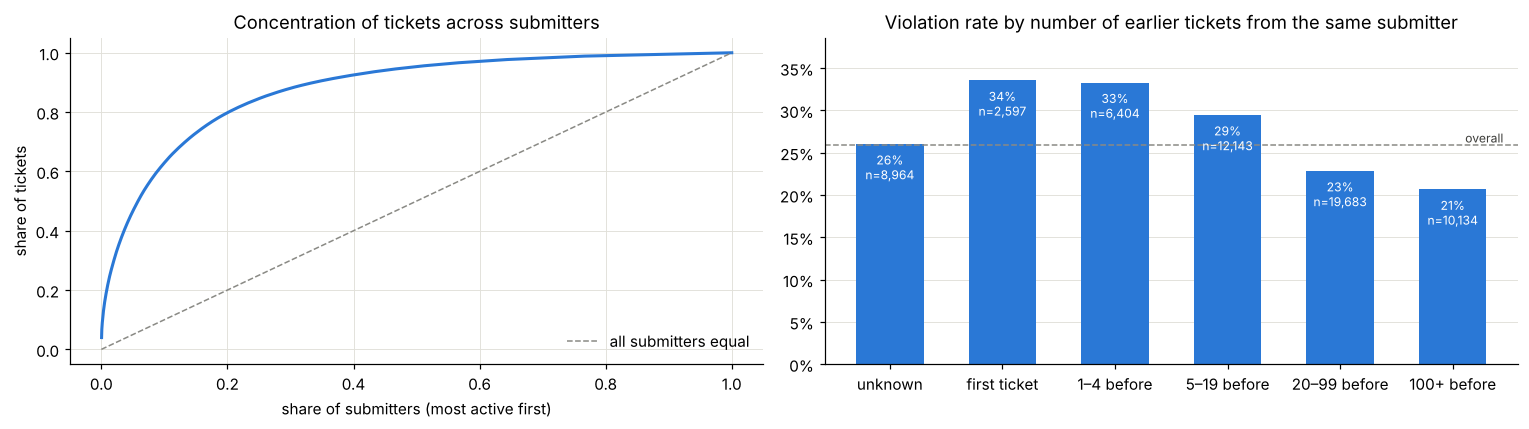

In [12]:
sub = df["SUBMITTED_BY_ID"].dropna()
counts = sub.value_counts().values
cum = np.cumsum(counts) / counts.sum()
share_sub = np.arange(1, len(counts) + 1) / len(counts)
print(f"submitters: {len(counts):,} | tickets without submitter: {df['SUBMITTED_BY_ID'].isna().mean():.1%}")
for k in [10, 100]:
    print(f"top {k} submitters open {cum[k - 1]:.1%} of the tickets with a known submitter")
print(f"submitters with at least 20 tickets: {(counts >= 20).sum():,}, covering {counts[counts >= 20].sum() / counts.sum():.1%} of those tickets")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(share_sub, cum, color=BLUE, lw=2)
axes[0].plot([0, 1], [0, 1], color=GRAY, lw=1, ls="--", label="all submitters equal")
axes[0].set_xlabel("share of submitters (most active first)"); axes[0].set_ylabel("share of tickets")
axes[0].set_title("Concentration of tickets across submitters"); axes[0].legend(frameon=False, loc="lower right")

bins = [-2, -0.5, 0.5, 4.5, 19.5, 99.5, np.inf]
names = ["unknown", "first ticket", "1–4 before", "5–19 before", "20–99 before", "100+ before"]
b = pd.cut(lab["submitter_prev_tickets"], bins, labels=names)
g = lab.groupby(b, observed=True)["viol"].agg(["mean", "size"])
axes[1].bar(g.index.astype(str), g["mean"], color=BLUE, width=0.6)
for x, (r, n) in enumerate(zip(g["mean"], g["size"])):
    axes[1].text(x, r - 0.01, f"{r:.0%}\nn={n:,}", ha="center", va="top", fontsize=8, color="white")
axes[1].axhline(overall, color=GRAY, lw=1, ls="--")
axes[1].set_ylim(0, g["mean"].max() * 1.15); axes[1].grid(axis="x", visible=False)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].text(5.45, overall, "overall", fontsize=8, color=INK, va="bottom", ha="right")
axes[1].set_title("Violation rate by number of earlier tickets from the same submitter")
plt.tight_layout(); plt.show()

**Reading.** 2,662 submitters, very concentrated: the 100 most active ones open 41% of the tickets with a known submitter, and the 600 with at least 20 tickets cover 82%. The violation rate falls with the submitter's experience, from 34% on a first ticket to 21% after 100 tickets. This explains why `SUBMITTED_BY_ID` is the most important feature, and why the model has to be checked on new submitters, for whom this information does not exist.

## 8. Link between the two targets
Each point is a closed ticket with an SLA: nominal deadline length against actual resolution time. Points above the diagonal took longer than the nominal deadline.

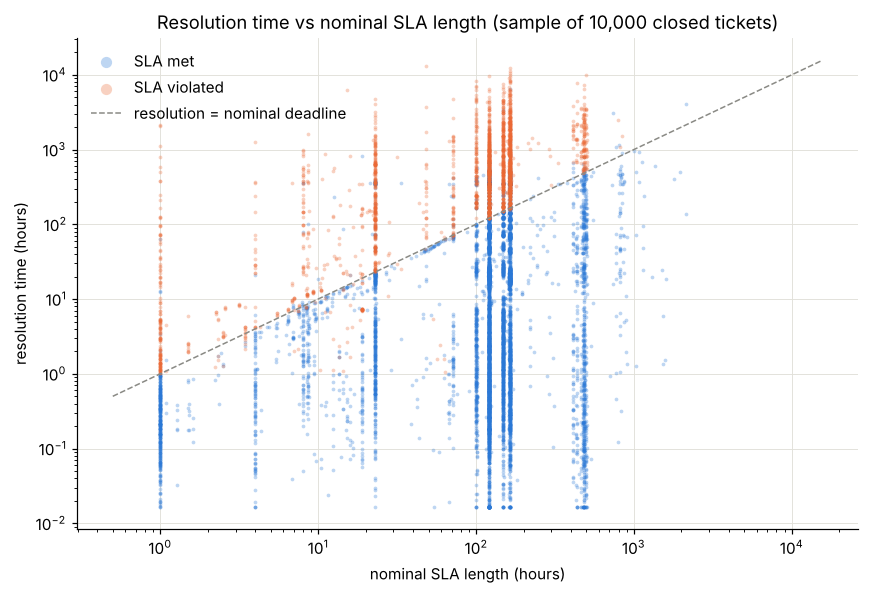

closed tickets above the diagonal: 28.8% | violation rate above: 83.5% | below: 0.9%


In [13]:
both = df[df["res_hours"].notna() & df["viol"].notna() & df["sla_nominal"].notna()]
smp = both.sample(min(10_000, len(both)), random_state=SEED)
fig, ax = plt.subplots(figsize=(8, 5.5))
for v, col, name in [(0, BLUE, "SLA met"), (1, ORANGE, "SLA violated")]:
    s = smp[smp["viol"] == v]
    ax.scatter(s["sla_nominal"].clip(lower=0.1), s["res_hours"].clip(lower=1 / 60), s=6, alpha=0.3,
               color=col, label=name, linewidths=0)
lim = [0.5, both["res_hours"].max()]
ax.plot(lim, lim, color=GRAY, lw=1, ls="--", label="resolution = nominal deadline")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("nominal SLA length (hours)"); ax.set_ylabel("resolution time (hours)")
ax.set_title("Resolution time vs nominal SLA length (sample of 10,000 closed tickets)")
ax.legend(frameon=False, markerscale=3, loc="upper left")
plt.tight_layout(); plt.show()

above = both["res_hours"] > both["sla_nominal"]
print(f"closed tickets above the diagonal: {above.mean():.1%} | violation rate above: "
      f"{both.loc[above, 'viol'].mean():.1%} | below: {both.loc[~above, 'viol'].mean():.1%}")

**Reading.** The vertical columns are the few standard SLA lengths. Closed tickets above the diagonal (28.8%) are violated in 83.5% of the cases, those below in 0.9%: a good prediction of the resolution time already gives most of the violation prediction. The two tasks are therefore linked, which is what the baseline notebook exploits (section 7) and what the survival model does in notebook 02.

## 9. Key takeaways for the modelling

1. **Temporal split.** Volume and ticket mix change over time, so train, validation and test are split by date, not at random.
2. **Labels need care.** Only Incidents and Service Requests have an SLA; never-closed tickets past their deadline are counted as violated, and 9% of the deadlines are extended later, so the deadline used as a feature is the nominal one.
3. **Log scale for time.** Resolution times range from seconds to months, so the regression works on `log1p(hours)` and reports relative errors.
4. **Censoring.** 5% of the tickets are never closed; dropping them biases the regression towards short tickets, hence the survival models in notebook 02.
5. **Strongest signals:** ticket type, SLA length, channel, hour and day of submission, and the submitter's history.
6. **Weak or post-hoc features:** `IMPACT_VALUE` hardly varies; `STATUS_EN`, `nb_actions` and `LAST_DONE_BY_ID` are known only after closure and are used only as an "oracle" upper bound.
7. **Questions for EasyVista:** the 14–15-day closures, the tickets without origin, and the meaning of never-closed tickets.